# Segmentação de Clientes com K-Means

**Profissão: Cientista de Dados (EBAC), Módulo 33**

Projeto de aprendizado não supervisionado: agrupar os clientes de um shopping em segmentos com comportamento semelhante, a partir da renda anual e da pontuação de gastos, para orientar ações de marketing diferenciadas por grupo.

**Etapas**

1. Análise exploratória
2. Pré-processamento (padronização)
3. Escolha do número de clusters (método do cotovelo e silhouette score)
4. K-Means com 3, 4 e 5 clusters
5. Perfil dos segmentos e recomendações de marketing

## 1. Importação de bibliotecas e dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

In [2]:
base = pd.read_csv('../data/Mall_Customers.csv')
base.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Análise exploratória

A base tem 200 clientes e cinco colunas: identificador, gênero, idade, renda anual (em milhares de dólares) e pontuação de gastos (1 a 100), atribuída pelo shopping com base no comportamento de compra.

In [3]:
base.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [4]:
base.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
# Não há valores ausentes
base.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

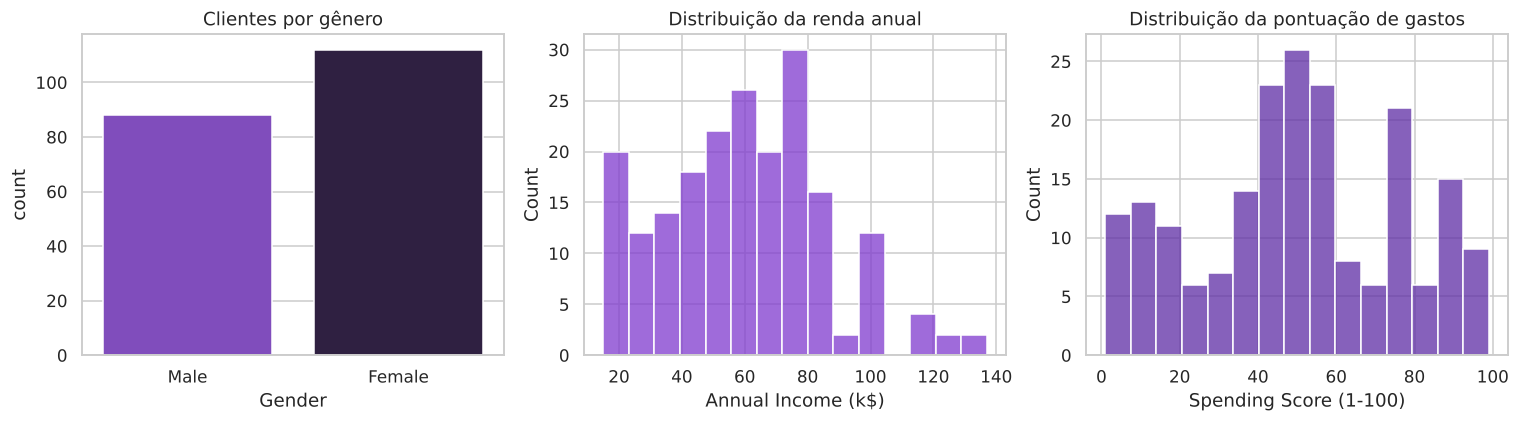

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=base, x='Gender', hue='Gender', palette=['#7F3ACE', '#2E1A47'], legend=False, ax=axes[0])
axes[0].set_title('Clientes por gênero')
sns.histplot(base['Annual Income (k$)'], bins=15, color='#7F3ACE', ax=axes[1])
axes[1].set_title('Distribuição da renda anual')
sns.histplot(base['Spending Score (1-100)'], bins=15, color='#5E2CA5', ax=axes[2])
axes[2].set_title('Distribuição da pontuação de gastos')
plt.tight_layout()
plt.show()

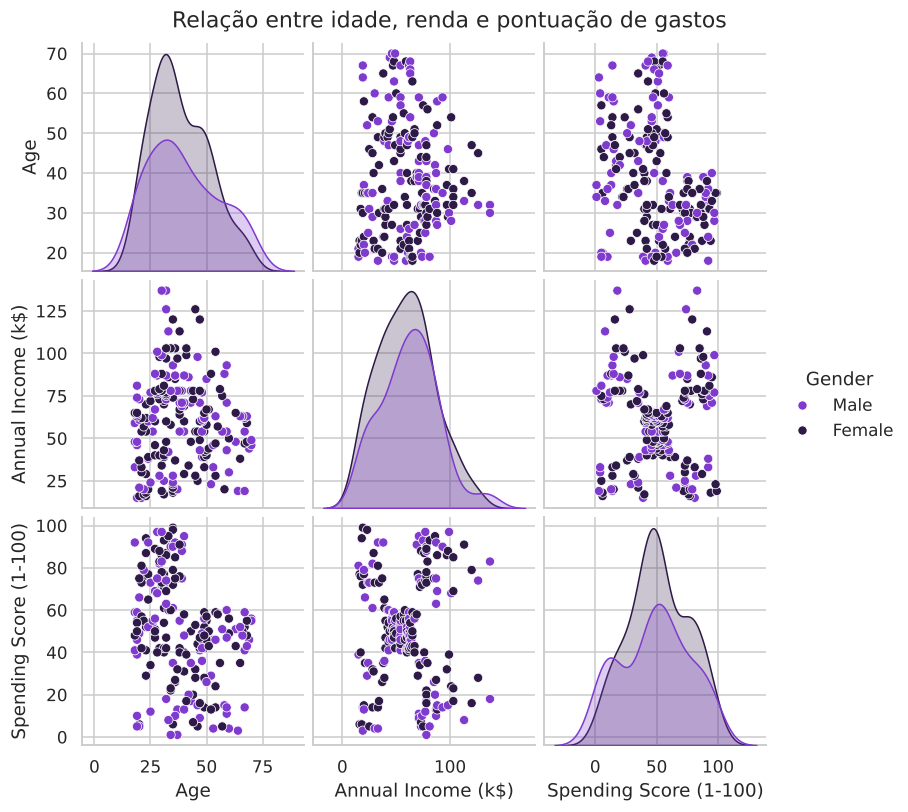

In [7]:
g = sns.pairplot(base.drop(columns='CustomerID'), hue='Gender', palette=['#7F3ACE', '#2E1A47'], height=2.4)
g.fig.suptitle('Relação entre idade, renda e pontuação de gastos', y=1.02)
plt.show()

**Leitura dos gráficos**

Ao analisar a relação entre renda e pontuação de gastos, é possível perceber uma concentração de clientes com score próximo de 50 e renda entre 40 e 70 mil dólares, e, visualmente, grupos bem definidos nos cantos do gráfico. Em relação à idade e ao score, as maiores pontuações são de pessoas entre 20 e 40 anos; a partir dos 40 anos o score fica, no máximo, em torno de 60. A base está equilibrada entre os gêneros (112 mulheres e 88 homens) e não há valores ausentes.

## 3. Pré-processamento

O K-Means usa distância euclidiana, por isso as variáveis precisam estar na mesma escala. A renda (15 a 137) e o score (1 a 99) foram padronizados com `StandardScaler` (média 0 e desvio padrão 1).

A segmentação usa apenas **renda anual** e **pontuação de gastos**: são as variáveis que descrevem o comportamento de compra e que apresentaram estrutura de grupos na análise exploratória. Idade e gênero ficam de fora do modelo e são usados depois para descrever os segmentos.

In [8]:
colunas = ['Annual Income (k$)', 'Spending Score (1-100)']

scaler = StandardScaler()
X = scaler.fit_transform(base[colunas])

X_df = pd.DataFrame(X, columns=colunas)
X_df.describe().round(2)

,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


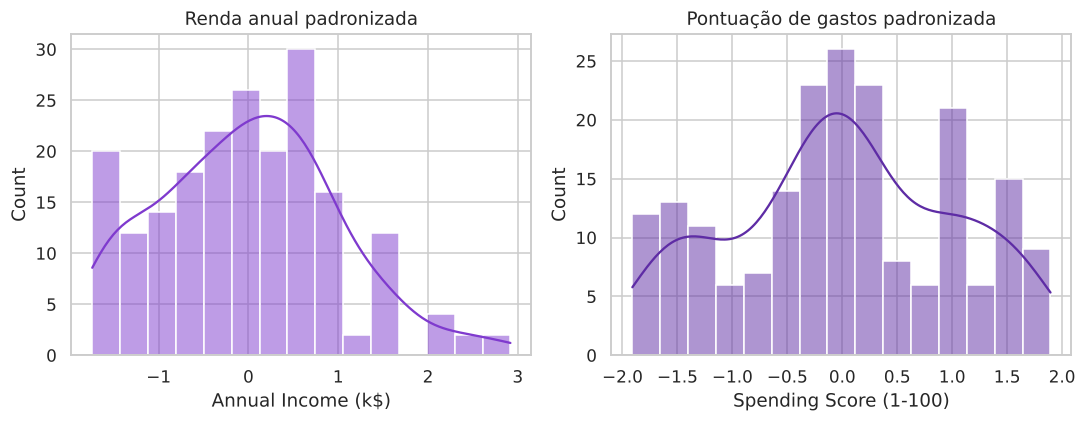

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(X_df['Annual Income (k$)'], bins=15, color='#7F3ACE', kde=True, ax=axes[0])
axes[0].set_title('Renda anual padronizada')
sns.histplot(X_df['Spending Score (1-100)'], bins=15, color='#5E2CA5', kde=True, ax=axes[1])
axes[1].set_title('Pontuação de gastos padronizada')
plt.tight_layout()
plt.show()

Após a padronização, a pontuação de gastos mostra um comportamento próximo de uma curva gaussiana, com concentração na região central (score 50), próxima à média.

## 4. Escolha do número de clusters

Dois critérios foram usados em conjunto:

* **Método do cotovelo**: a inércia (soma das distâncias quadráticas de cada ponto ao seu centróide) cai conforme k aumenta; o "cotovelo" indica o ponto a partir do qual adicionar clusters traz pouco ganho.
* **Silhouette score**: mede, de -1 a 1, o quanto cada ponto está mais próximo do próprio cluster do que do cluster vizinho. Quanto maior, melhor separados estão os grupos.

In [10]:
inercias = []
silhuetas = []
ks = range(2, 11)

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X, km.labels_))

resultado_k = pd.DataFrame({'k': ks, 'inercia': np.round(inercias, 1), 'silhouette': np.round(silhuetas, 3)})
resultado_k

,k,inercia,silhouette
0,2,269.7,0.321
1,3,157.7,0.467
2,4,108.9,0.494
3,5,65.6,0.555
4,6,55.1,0.540
5,7,44.9,0.528
6,8,37.2,0.455
7,9,32.4,0.457
8,10,30.0,0.443


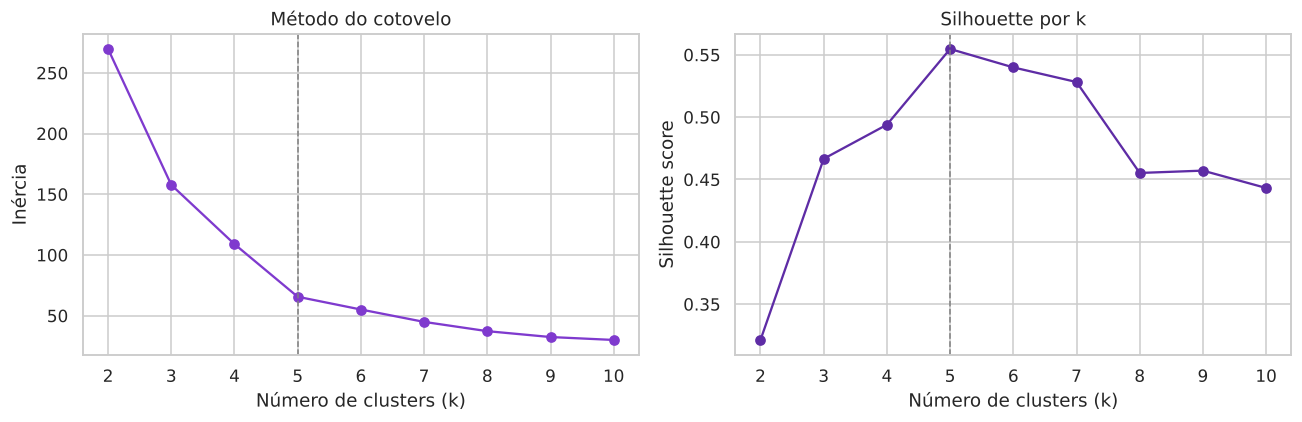

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inercias, marker='o', color='#7F3ACE')
axes[0].axvline(5, color='grey', ls='--', lw=1)
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inércia')
axes[0].set_title('Método do cotovelo')
axes[1].plot(ks, silhuetas, marker='o', color='#5E2CA5')
axes[1].axvline(5, color='grey', ls='--', lw=1)
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette por k')
plt.tight_layout()
plt.show()

Os dois critérios apontam para **k = 5**: a curva de inércia perde inclinação a partir desse ponto e o silhouette score atinge o máximo (0,555). A seguir, os resultados com 3, 4 e 5 clusters são comparados para mostrar como a segmentação evolui.

## 5. K-Means

In [12]:
def rodar_kmeans(k):
    """Treina o K-Means com k clusters e devolve o modelo, os rótulos e os centróides na escala original."""
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    centroides = scaler.inverse_transform(km.cluster_centers_)
    return km, km.labels_, centroides


def plotar_clusters(labels, centroides, titulo):
    """Dispersão renda x score colorida por cluster, com os centróides em destaque."""
    df = base.assign(cluster=labels.astype(str))
    plt.figure(figsize=(8, 5.5))
    sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='cluster',
                    palette='viridis', s=55, alpha=0.85)
    plt.scatter(centroides[:, 0], centroides[:, 1], c='red', marker='D', s=120, label='Centróides', zorder=5)
    plt.title(titulo)
    plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

### 5.1 Três clusters

Centróides (renda, score):
[[87.  18.6]
 [86.5 82.1]
 [44.2 49.8]]


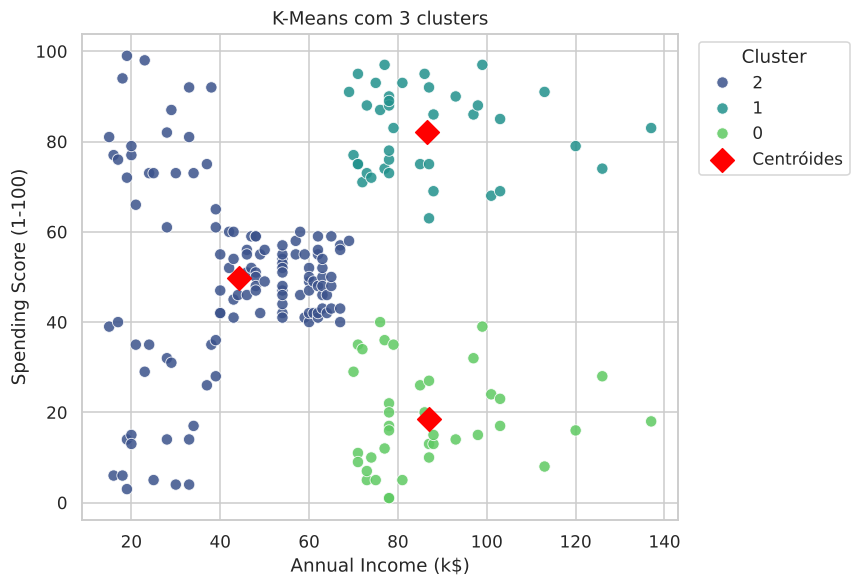

In [13]:
km3, labels3, cent3 = rodar_kmeans(3)
print('Centróides (renda, score):')
print(np.round(cent3, 1))
plotar_clusters(labels3, cent3, 'K-Means com 3 clusters')

**Insight com 3 clusters**

É possível perceber a divisão em que um grupo representa pessoas com renda anual até cerca de 70 mil, com um perfil único em relação às pessoas com renda acima de 70 mil. De 70 mil para cima, há dois clusters relacionados ao score: ou o score é baixo ou é alto, não "na média". Pessoas de renda alta e score baixo podem ser incentivadas com promoções de produtos exclusivos, já que este grupo possui renda e é possível entregar algo de valor percebido.

### 5.2 Quatro clusters

Centróides (renda, score):
[[26.3 20.9]
 [87.  18.6]
 [48.3 56.5]
 [86.5 82.1]]


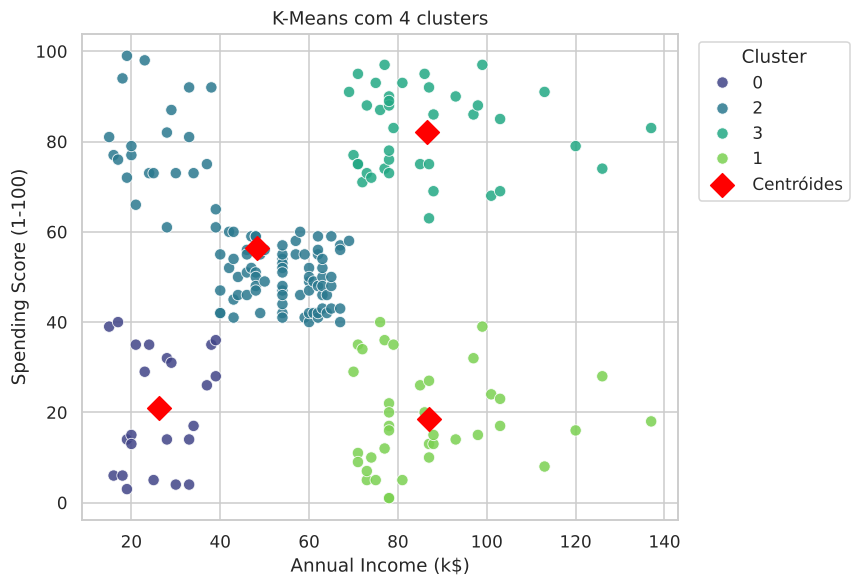

In [14]:
km4, labels4, cent4 = rodar_kmeans(4)
print('Centróides (renda, score):')
print(np.round(cent4, 1))
plotar_clusters(labels4, cent4, 'K-Means com 4 clusters')

**Insight com 4 clusters**

Os clusters acima de 70 mil se mantiveram; o grupo abaixo de 70 mil foi dividido entre as pessoas com score baixo e outro que engloba score médio e alto. Pessoas com renda baixa e score baixo podem receber promoções de estoque antigo.

### 5.3 Cinco clusters (modelo final)

Centróides (renda, score):
[[55.3 49.5]
 [86.5 82.1]
 [25.7 79.4]
 [88.2 17.1]
 [26.3 20.9]]


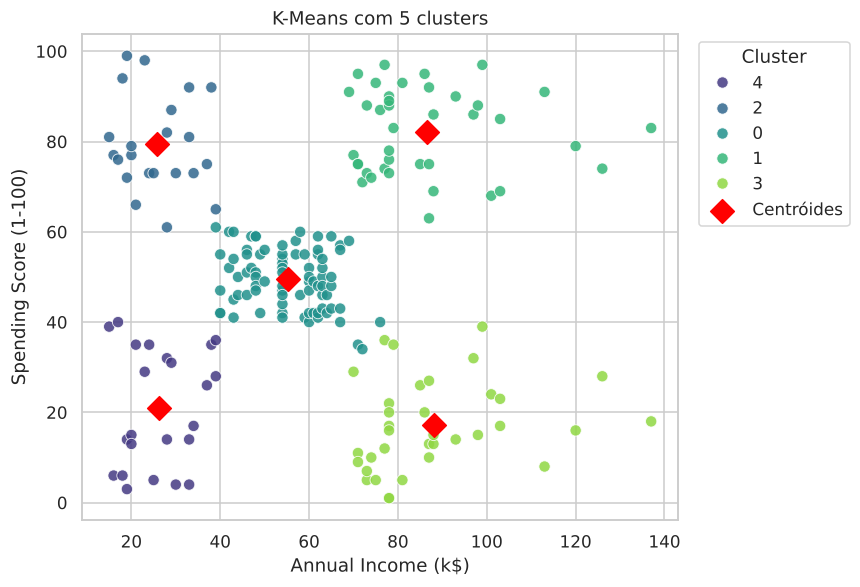

In [15]:
km5, labels5, cent5 = rodar_kmeans(5)
print('Centróides (renda, score):')
print(np.round(cent5, 1))
plotar_clusters(labels5, cent5, 'K-Means com 5 clusters')

**Insight com 5 clusters**

Agora a separação aparece de maneira bem destacada e com os centróides bem posicionados: o grupo central (renda e score médios) fica isolado, e os quatro cantos do gráfico formam grupos próprios. É a melhor clusterização, em concordância com o método do cotovelo e com o silhouette score.

## 6. Perfil dos segmentos

Com os rótulos do modelo final, cada segmento é descrito pelas variáveis usadas no modelo e também por idade e gênero, que ficaram de fora do treinamento.

In [16]:
base_seg = base.assign(cluster=labels5)

perfil = (base_seg.groupby('cluster')
          .agg(clientes=('CustomerID', 'count'),
               renda_media=('Annual Income (k$)', 'mean'),
               score_medio=('Spending Score (1-100)', 'mean'),
               idade_media=('Age', 'mean'),
               pct_mulheres=('Gender', lambda s: (s == 'Female').mean() * 100))
          .round(1))

# Nome de cada segmento a partir do centróide
def nomear(row):
    renda = 'alta' if row['renda_media'] > 70 else ('baixa' if row['renda_media'] < 40 else 'média')
    score = 'alto' if row['score_medio'] > 60 else ('baixo' if row['score_medio'] < 40 else 'médio')
    return f'Renda {renda}, gasto {score}'

perfil['segmento'] = perfil.apply(nomear, axis=1)
perfil = perfil.sort_values(['renda_media', 'score_medio'], ascending=[False, False])
perfil

,clientes,renda_media,score_medio,idade_media,pct_mulheres,segmento
cluster,,,,,,
3,35,88.2,17.1,41.1,45.7,"Renda alta, gasto baixo"
1,39,86.5,82.1,32.7,53.8,"Renda alta, gasto alto"
0,81,55.3,49.5,42.7,59.3,"Renda média, gasto médio"
4,23,26.3,20.9,45.2,60.9,"Renda baixa, gasto baixo"
2,22,25.7,79.4,25.3,59.1,"Renda baixa, gasto alto"


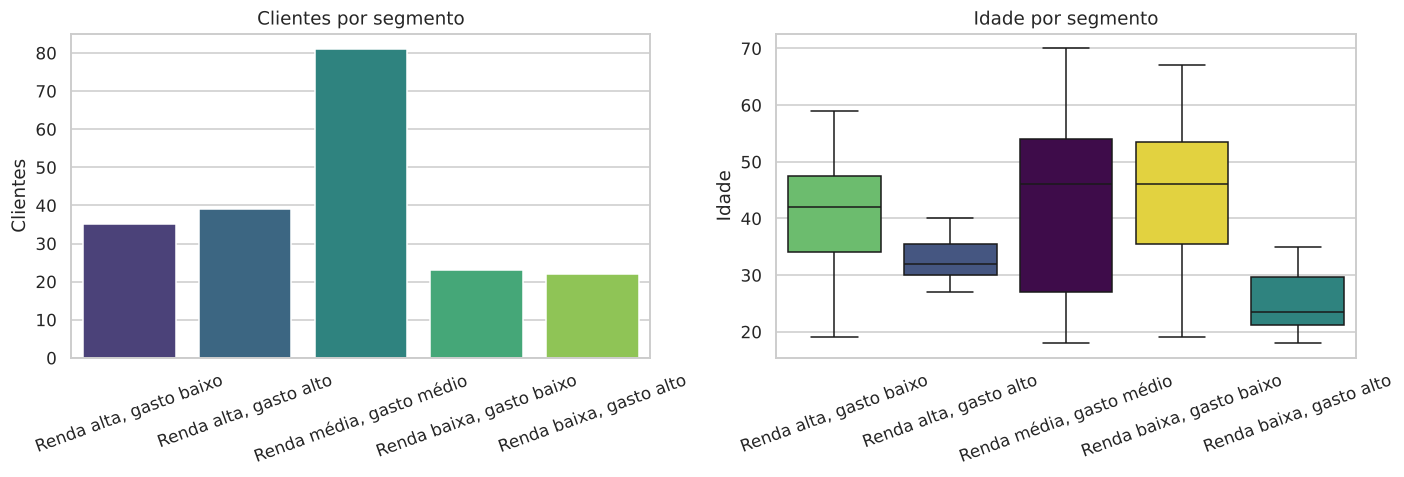

In [17]:
ordem = perfil.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=perfil['segmento'], y=perfil['clientes'], hue=perfil['segmento'], palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Clientes por segmento')
axes[0].set_xlabel('')
axes[0].set_ylabel('Clientes')
axes[0].tick_params(axis='x', rotation=20)
sns.boxplot(data=base_seg, x='cluster', y='Age', order=ordem, hue='cluster', hue_order=ordem, palette='viridis', legend=False, ax=axes[1])
axes[1].set_ylabel('Idade')
axes[1].set_xticks(range(len(ordem)))
axes[1].set_xticklabels([perfil.loc[c, 'segmento'] for c in ordem], rotation=20)
axes[1].set_title('Idade por segmento')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

**Recomendações por segmento**

| Segmento | Perfil | Ação sugerida |
|:--|:--|:--|
| Renda alta, gasto alto | Clientes mais valiosos, em média com 32 anos | Programa de fidelidade, lançamentos e atendimento prioritário para manter a frequência |
| Renda alta, gasto baixo | Têm renda, mas gastam pouco no shopping; média de 41 anos | Produtos exclusivos e experiências de valor percebido, campanhas de reativação |
| Renda média, gasto médio | Maior grupo (81 clientes), comportamento regular | Promoções sazonais e cross-sell para elevar o ticket médio |
| Renda baixa, gasto alto | Jovens (média de 25 anos) que gastam acima da renda | Parcelamento, cashback e produtos de entrada; cuidado com inadimplência |
| Renda baixa, gasto baixo | Menor valor atual, média de 45 anos | Ofertas de estoque antigo e promoções de preço, com baixo investimento em marketing |

## 7. Conclusão

* O K-Means com **5 clusters** foi o modelo final, escolha sustentada por três evidências: método do cotovelo, silhouette score máximo (0,555) e separação visual clara dos grupos.
* A padronização das variáveis foi necessária porque renda e score têm escalas diferentes e o algoritmo é baseado em distância.
* Os cinco segmentos têm perfis distintos de renda, gasto e idade, o que permite ações de marketing específicas em vez de uma campanha única para toda a base.
* Limitações: a base é pequena (200 clientes) e a segmentação usa apenas duas variáveis. Próximos passos: incluir idade e frequência de visitas no modelo, testar algoritmos hierárquicos e DBSCAN, e validar os segmentos com dados reais de campanhas.